# Cromosim - Microscopic model - Tutorial 02 — Microscopic granular model

This notebook introduces the `cromosim.micro` module using the current **Cromosim 3.1.2** API from the project repository.

The goal here is to set up a simulation for the microscopic granular model, which requires a step to map the velocities onto the set of admissible velocities.

## 1. Create a domain

We first build the geometry directly in Python. This is the same information that is usually described in the configuration files used by the Cromosim examples: the domain contains the geometric description of the room, the wall colors, and the destinations.

For more details on domains and destinations, see Tutorial 01 and the JSON files located in the examples folder.

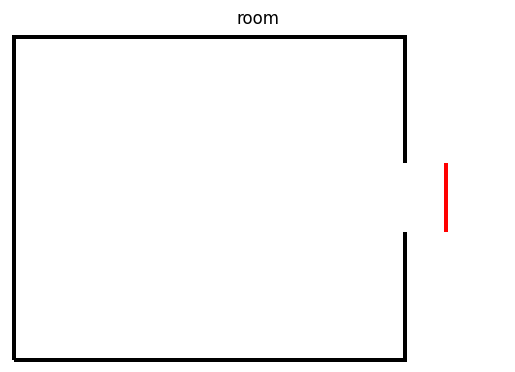

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from cromosim.domain import Domain, Destination

def build_room(name="room", pixel_size=0.05, width=240, height=160, destination_name="exit"):
    """Create a room with one exit in the right wall."""
    dom = Domain(
        name=name,
        background="White",
        pixel_size=pixel_size,
        width=width,
        height=height,
        wall_colors=[[0, 0, 0]],
    )

    lx = 0.8*width * pixel_size
    ly = height * pixel_size
    eps = 1.5 * pixel_size

    # Boundary walls. The right wall is drawn first; the red exit drawn below
    # overwrites a small part of it.
    walls = [
        Line2D([eps, lx-eps], [eps, eps], linewidth=2),
        Line2D([eps, lx-eps], [ly-eps, ly-eps], linewidth=2),
        Line2D([eps, eps], [eps, ly-eps], linewidth=2),
        Line2D([lx-eps, lx-eps], [eps, ly-eps], linewidth=2),
    ]
    for wall in walls:
        dom.add_shape(wall, outline_color=[0, 0, 0])

    # An exit centered on the right wall.
    door = Line2D([lx, lx],[0.5*ly-0.8, 0.5*ly+0.8], linewidth=8, )
    dom.add_shape(door, outline_color=[255, 255, 255])
    destination = Line2D([1.1*lx, 1.1*lx],[0.5*ly-0.8, 0.5*ly+0.8], linewidth=2, )
    dom.add_shape(destination, outline_color=[255, 0, 0])

    dom.build_domain()
    dom.add_destination(
        Destination(
            name=destination_name,
            colors=[[255, 0, 0]],
            excluded_colors=[[0, 0, 0]],
        )
    )
    return dom

pixel_size=0.05 
destination_name="exit"

dom = build_room(name="room", pixel_size=pixel_size, destination_name=destination_name)
dom.plot(title="room")

## 2.  Initialization

Before running the granular model, we need to describe the pedestrians. 

In [8]:
print(dom)

## Number of pedestrians
N = 40

## Positions / radius / speed
xyrv = np.zeros((N,4))
gen = np.random.default_rng(seed=10)
eps = 5*dom.pixel_size
xyrv[:,0] = gen.uniform(dom.xmin+eps, dom.xmax-eps, N)
xyrv[:,1] = gen.uniform(dom.ymin+eps, dom.ymax-eps, N)
xyrv[:,2] = gen.uniform(0.3, 0.4, N)
xyrv[:,3] = gen.uniform(0.7, 1.2, N)
#print(xyrv)

## The same destination for everyone!
destinations = np.array([destination_name] * N)

## The same weight for everyone!
mass = np.full(N, 80.0) # 80kg :-)

people = {}
people["xyrv"] = xyrv
people["mass"] = mass
people["destinations"] = destinations

--> room:
    dimensions: [0.0,12.0]x[0.0,8.0]
    width: 240 height: 160
    background image: White
    image of the domain: room_domain.png
    wall_colors: [[0, 0, 0]]
    destinations: {'exit': <cromosim.domain.Destination object at 0x10c6eb770>, 'door': <cromosim.domain.Destination object at 0x10e172990>}


## 3. From desired velocity to admissible velocity

The granular model does not move pedestrians directly with their desired velocity $V_d$.

For every time step, Cromosim:
1. Evaluates the desired velocity field associated with each pedestrian's destination;
2. Detects potentially active person-person and person-wall contacts (according to the parameter $dmax$);
3. Projects $V_d$ onto the set of admissible velocities, producing the new velocity $U$;
4. Moves the pedestrians with $U$.
The dictionary people is passed from one operation to the next and is enriched with quantities such as Vd and U. 

number of contacts: 65


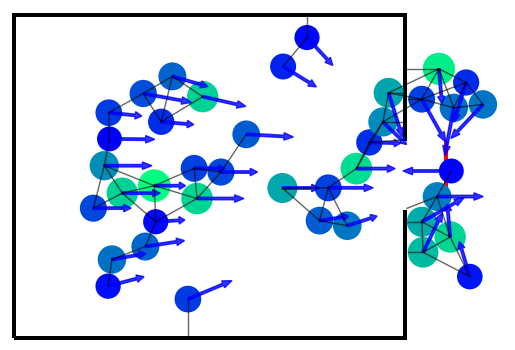

Uzawa number of iterations / info: 276


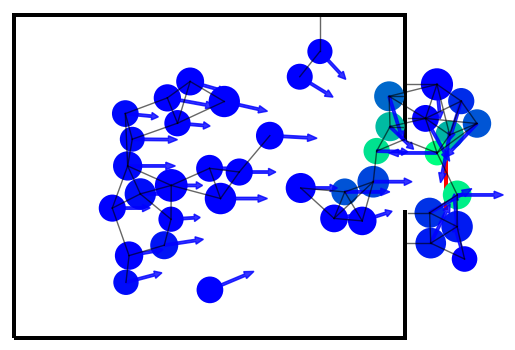

In [10]:
## Simulation Parameters

# Time step
dt = 0.5

# Maximum distance used when searching for contacts between individuals
dmax = 0.60

# Minimum permitted distance between people
dmin_people = 0.0
# Minimum permitted distance between a person and a wall
dmin_walls = 0.0

# Start by one projection step

from cromosim.micro import compute_contacts, projection

_, _, Vd = dom.people_desired_velocity(people["xyrv"], people["destinations"])
people["Vd"] = Vd

contacts = compute_contacts(dom, people["xyrv"], dmax=dmax)
print("number of contacts:", len(contacts))

## Draw people BEFORE the projection step

from cromosim.visu import plot_people
colors = xyrv[:,2]
plot_people(1, dom, people, contacts, colors, plot_desired_velocities=True)
plt.show()

info, B, U, L, P, _ = projection(
    dt,
    people["xyrv"],
    contacts,
    people["Vd"],
    people["mass"],
    dmin_people=dmin_people,
    dmin_walls=dmin_walls,
    method="uzawa",
    rho=5.0,
    tol=1.0e-3,
    log=True,
)

print("Uzawa number of iterations / info:", info)

## Draw people AFTER the projection step

# Move people
people["xyrv"][:, :2] += dt*U 

people["U"] = U
colors = P

# update contacts (just for correct visualization...)
contacts = compute_contacts(dom, people["xyrv"], dmax=dmax)
plot_people(1, dom, people, contacts, colors, plot_desired_velocities=True)
plt.show()


## 3. Simulate several seconds - Animate the simulation

We now use the higher-level initialization routine people_initialization and run the full granular loop for several seconds.

The variable population_groups below is particularly close to what you will find in the JSON files of the Cromosim examples. Each dictionary describes how one group of pedestrians should be generated.
At every step we compute the contacts, the admissible velocity and the new positions. This is the core granular loop.


In [11]:
from cromosim.micro import (
    people_initialization,
    compute_contacts,
    projection,
    move_people,
    people_update_destination,
)
from cromosim.visu import matplotlibVisualization
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Time discretization
DT = 0.03
FINAL_TIME = 16.0

# Contact/projection parameters
DMAX = 0.08
DMIN_PEOPLE = 0.0
DMIN_WALLS = 0.0
PROJECTION_METHOD = "uzawa"

# Save only one state every few time steps so that the notebook animation
# remains reasonably light.
SAVE_EVERY = 5

DOOR_COLOR = [255,0,0]
WALL = [0,0,0]
destination = Destination(
    name = "door",
    colors =[ DOOR_COLOR ],
    excluded_colors = [ WALL ],
    desired_velocity_from_color = [],
    velocity_scale = 1,
    next_destination = [None], 
    next_domain = [None], 
    next_destination_weights = [1.0], 
    next_transit_box =         [None], 
    next_transit_box_xshift =  [0.0], 
    next_transit_box_yshift =  [0.0]
)
dom.add_destination(destination)

population_groups = [
    {
        "nb": 30,
        "flux_per_minute": False,
        "radius_distribution": ["uniform", 0.20, 0.30],
        "velocity_distribution": ["normal", 1.00, 0.20],
        "viewing_angle_distribution": ["uniform", 40.0, 60.0],
        "mass_distribution": ["uniform", 80.0, 80.0],
        "box": [dom.xmin+eps, dom.xmax-eps, dom.ymin+eps, dom.ymax-eps],
        "color_for_positions": [],
        "destination": "door",
        "with_frustration": False,
    }
]

people = people_initialization(
    dom,
    population_groups,
    DT,
    dmin_people=DMIN_PEOPLE,
    dmin_walls=DMIN_WALLS,
    seed=1234,
    itermax=20,
    projection_method=PROJECTION_METHOD,
    log=False,
)

print("Initial number of pedestrians:", people["xyrv"].shape[0])

# people_update_destination works with dictionaries indexed by domain name.
domains = {dom.name: dom}
all_people = {dom.name: people}

history = []
t = 0.0
step = 0

while t < FINAL_TIME and all_people[dom.name]["xyrv"].shape[0] > 0:
    people = all_people[dom.name]

    # 1) Desired velocities associated with the current destinations.
    _, _, Vd = dom.people_desired_velocity(
        people["xyrv"],
        people["destinations"],
    )
    people["Vd"][:, 0] = people["beta"] * Vd[:, 0]
    people["Vd"][:, 1] = people["beta"] * Vd[:, 1]

    # 2) Active person-person and person-wall contacts.
    contacts = compute_contacts(
        dom,
        people["xyrv"],
        DMAX,
    )

    # 3) Granular projection: Vd -> admissible velocity U.
    info, B, U, L, P, frustration = projection(
        DT,
        people["xyrv"],
        contacts,
        people["Vd"],
        people["mass"],
        dmin_people=DMIN_PEOPLE,
        dmin_walls=DMIN_WALLS,
        method=PROJECTION_METHOD,
        log=False,
    )

    people["U"][:] = U
    people["frustration"][:] = frustration

    # Save the state BEFORE moving. Contacts therefore correspond exactly
    # to the positions shown in that animation frame.
    if step % SAVE_EVERY == 0:
        history.append(
            {
                "time": t,
                "xyrv": people["xyrv"].copy(),
                "U": people["U"].copy(),
                "Vd": people["Vd"].copy(),
                "frustration": people["frustration"].copy(),
                "contacts": np.asarray(contacts).copy(),
            }
        )

    # 4) Move pedestrians with the projected velocity.
    people, _ = move_people(t, DT, people, [])
    all_people[dom.name] = people

    # 5) Remove pedestrians that have reached their final destination.
    all_people = people_update_destination(
        all_people,
        domains,
        thld=2.0 * DT,
    )

    t += DT
    step += 1

print(f"Stored frames: {len(history)}")
print(f"Remaining pedestrians at t={t:.2f} s:",
      all_people[dom.name]["xyrv"].shape[0])





Initial number of pedestrians: 30
Stored frames: 85
Remaining pedestrians at t=12.75 s: 0


### Visualization and animation

The simulation above has already been computed. The history list stores selected snapshots of the dynamic state. We now replay those states with cromosim.visu.matplotlibVisualization.

This separation is useful in a notebook:
- the JSON/Python configuration defines the experiment;
- the simulation loop computes the evolving state;
- the visualization layer displays previously computed states.
Consequently, changing the animation settings does not require changing the granular model itself.

In [5]:
from cromosim.visu import matplotlibVisualization

viewer = matplotlibVisualization(
    dom,
    figsize=(11, 6),
    cmap="viridis",
    velocity_reference=1.5,
    velocity_arrow_length=0.55,
)


def animate(frame_index):
    state = history[frame_index]

    frame_people = {
        "xyrv": state["xyrv"],
        "U": state["U"],
        "Vd": state["Vd"],
    }

    viewer.update(
        people=frame_people,
        contacts=state["contacts"],
        time=state["time"],
        plot_people=True,
        plot_contacts=True,
        plot_velocities=True,
        plot_desired_velocities=False,
        plot_paths=False,
        color_scalar_values=state["frustration"],
        color_scalar_name="frustration",
        color_minmax=(0.0, 1.0),
        color_cmap="viridis",
        show_scalar_bar=True,
    )

    return []


animation = FuncAnimation(
    viewer.fig,
    animate,
    frames=len(history),
    interval=50,
    repeat=False,
)

plt.close(viewer.fig)
HTML(animation.to_jshtml())